<a href="https://colab.research.google.com/github/vandau16/THXDMHTTNT/blob/main/TUAN%203/Bai_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI 2 — HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI CHO WINE QUALITY

Notebook này chỉ giải **Bài 2** trong slide bằng dữ liệu `wine_quality_merged.csv`. Đặt file CSV cùng thư mục với notebook trước khi chạy.

## PHẦN A — THƯ VIỆN VÀ CẤU HÌNH

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, make_scorer
)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(model, X_data, y_data, cv=cv, scoring=scoring)
    result = {}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        result[f"{metric}_mean"] = values.mean()
        result[f"{metric}_std"] = values.std()
    return result
# Cấu hình giao diện biểu đồ đồng nhất (kiểu báo cáo học thuật sạch, lưới ngang mờ, bỏ viền trên/phải)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#EAEAEA",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 10
})

PALETTE_MAIN = ["#31708E", "#9CB4C2", "#B57B56", "#5E8B7E"]

def style_ax(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, axis=grid_axis, color="#EAEAEA", linewidth=0.7)
    ax.set_axisbelow(True)
    return ax

---

# BÀI 2 — HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI CHO WINE QUALITY

## 2.1. Mục tiêu và quy ước nhãn

Dữ liệu có điểm `quality` từ 3 đến 9 và cột `type` (red/white). Chuyển thành bài toán nhị phân:

- `quality >= 7`: Good (1)
- `quality < 7`: Not Good (0)

Đây là quy ước thực nghiệm để thực hiện classification; không phải nhãn gốc của file.

## 2.2. Đọc dữ liệu

In [7]:
# Đọc CSV cùng thư mục với notebook
df_wine = pd.read_csv("wine_quality_merged.csv")

print("Kích thước:", df_wine.shape)
display(df_wine.head())
print("\nThông tin dữ liệu:")
df_wine.info()

Kích thước: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


## 2.3. Khám phá dữ liệu (EDA)

In [8]:
print("Số giá trị thiếu:", df_wine.isna().sum().sum())
print("Số dòng trùng lặp:", df_wine.duplicated().sum())
display(df_wine.describe(include="all").T)
print("\nPhân bố quality:")
display(df_wine["quality"].value_counts().sort_index())
print("\nPhân bố loại rượu:")
display(df_wine["type"].value_counts())

Số giá trị thiếu: 0
Số dòng trùng lặp: 1177


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,NaN,NaN,NaN,7.215307,1.296434,3.8,6.4,7.0,7.7,15.9
volatile acidity,6497.0,NaN,NaN,NaN,0.339666,0.164636,0.08,0.23,0.29,0.4,1.58
citric acid,6497.0,NaN,NaN,NaN,0.318633,0.145318,0.0,0.25,0.31,0.39,1.66
residual sugar,6497.0,NaN,NaN,NaN,5.443235,4.757804,0.6,1.8,3.0,8.1,65.8
chlorides,6497.0,NaN,NaN,NaN,0.056034,0.035034,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,NaN,NaN,NaN,30.525319,17.7494,1.0,17.0,29.0,41.0,289.0
total sulfur dioxide,6497.0,NaN,NaN,NaN,115.744574,56.521855,6.0,77.0,118.0,156.0,440.0
density,6497.0,NaN,NaN,NaN,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,NaN,NaN,NaN,3.218501,0.160787,2.72,3.11,3.21,3.32,4.01
sulphates,6497.0,NaN,NaN,NaN,0.531268,0.148806,0.22,0.43,0.51,0.6,2.0



Phân bố quality:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5



Phân bố loại rượu:


,count
type,
white,4898
red,1599


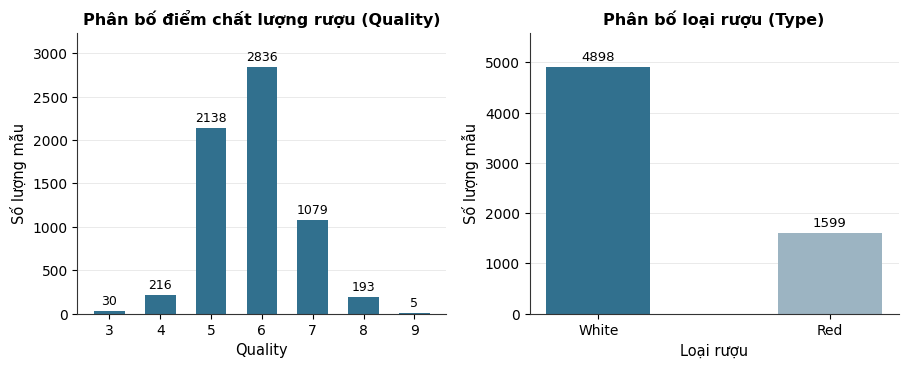

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))

q_counts = df_wine["quality"].value_counts().sort_index()
bars1 = axes[0].bar(q_counts.index.astype(str), q_counts.values, color="#31708E", width=0.6)
axes[0].set_title("Phân bố điểm chất lượng rượu (Quality)")
axes[0].set_xlabel("Quality")
axes[0].set_ylabel("Số lượng mẫu")
axes[0].set_ylim(0, q_counts.max() * 1.14)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 40, f"{int(b.get_height())}",
                 ha="center", va="bottom", fontsize=9)
style_ax(axes[0], "y")

t_counts = df_wine["type"].value_counts()
bars2 = axes[1].bar(t_counts.index.str.capitalize(), t_counts.values, color=["#31708E", "#9CB4C2"], width=0.45)
axes[1].set_title("Phân bố loại rượu (Type)")
axes[1].set_xlabel("Loại rượu")
axes[1].set_ylabel("Số lượng mẫu")
axes[1].set_ylim(0, t_counts.max() * 1.14)
for b in bars2:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 80, f"{int(b.get_height())}",
                 ha="center", va="bottom", fontsize=9.5)
style_ax(axes[1], "y")

plt.tight_layout()
plt.show()

## 2.4. Tạo target nhị phân và kiểm tra class imbalance

Tạo `target = 1` nếu quality từ 7 trở lên; ngược lại bằng 0. Kiểm tra tỷ lệ hai lớp trước khi huấn luyện.

,Số mẫu,Tỷ lệ (%)
Not Good (0),5220,80.34
Good (1),1277,19.66


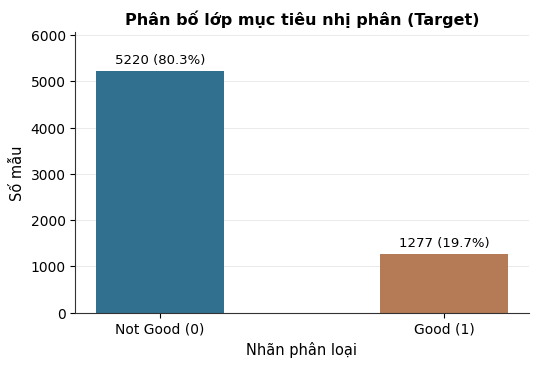

In [10]:
df_wine["target"] = (df_wine["quality"] >= 7).astype(int)

class_dist = pd.DataFrame({
    "Số mẫu": df_wine["target"].value_counts().sort_index(),
    "Tỷ lệ (%)": (df_wine["target"].value_counts(normalize=True).sort_index() * 100).round(2)
})
class_dist.index = ["Not Good (0)", "Good (1)"]
display(class_dist)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
counts = class_dist["Số mẫu"]
pcts = class_dist["Tỷ lệ (%)"]
bars = ax.bar(class_dist.index, counts.values, color=["#31708E", "#B57B56"], width=0.45)
ax.set_title("Phân bố lớp mục tiêu nhị phân (Target)")
ax.set_xlabel("Nhãn phân loại")
ax.set_ylabel("Số mẫu")
ax.set_ylim(0, counts.max() * 1.16)
for b, cnt, pct in zip(bars, counts.values, pcts.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 90, f"{cnt} ({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9.5)
style_ax(ax, "y")
plt.tight_layout()
plt.show()

## 2.5. Tiền xử lý và chia Train/Test

- Bỏ `quality` khỏi feature vì target được tạo trực tiếp từ quality. Nếu giữ lại sẽ gây **target leakage**.
- Giữ `type` và mã hóa one-hot.
- Chia train/test có `stratify=y`.
- Imputation, mã hóa và chuẩn hóa đặt trong Pipeline để tránh leakage.

In [11]:
X_wine = df_wine.drop(columns=["quality", "target"])
y_wine = df_wine["target"]

# Tách feature số và feature phân loại
numeric_features = X_wine.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_wine.select_dtypes(exclude=np.number).columns.tolist()

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocess, numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=RANDOM_STATE, stratify=y_wine
)

print("Train:", X_train_w.shape, "| Test:", X_test_w.shape)
print("Tỷ lệ Good trong train:", round(y_train_w.mean(), 4))
print("Tỷ lệ Good trong test:", round(y_test_w.mean(), 4))

Train: (5197, 12) | Test: (1300, 12)
Tỷ lệ Good trong train: 0.1965
Tỷ lệ Good trong test: 0.1969


## 2.6. Xây dựng và so sánh mô hình

So sánh Logistic Regression, KNN, SVM và Decision Tree bằng Stratified 5-Fold CV. Dùng các metric Accuracy, Precision, Recall, F1, ROC-AUC và PR-AUC. Lớp `Good (1)` là lớp positive.

In [12]:
wine_models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("preprocess", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("preprocess", preprocessor),
        ("model", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

wine_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
wine_cv_rows = []
for name, model in wine_models.items():
    row = cv_summary(model, X_train_w, y_train_w, wine_cv)
    row["Model"] = name
    wine_cv_rows.append(row)

wine_cv_table = pd.DataFrame(wine_cv_rows).set_index("Model")
display(wine_cv_table[[
    "accuracy_mean", "precision_mean", "recall_mean",
    "f1_mean", "roc_auc_mean", "pr_auc_mean"
]].sort_values("f1_mean", ascending=False).round(4))

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
Model,,,,,,
Decision Tree,0.8262,0.5548,0.5915,0.5717,0.7376,0.4094
KNN,0.8436,0.6184,0.5289,0.5700,0.8385,0.5597
SVM,0.8314,0.6665,0.2860,0.3992,0.8380,0.5831
Logistic Regression,0.8160,0.5712,0.2674,0.3630,0.8111,0.4968


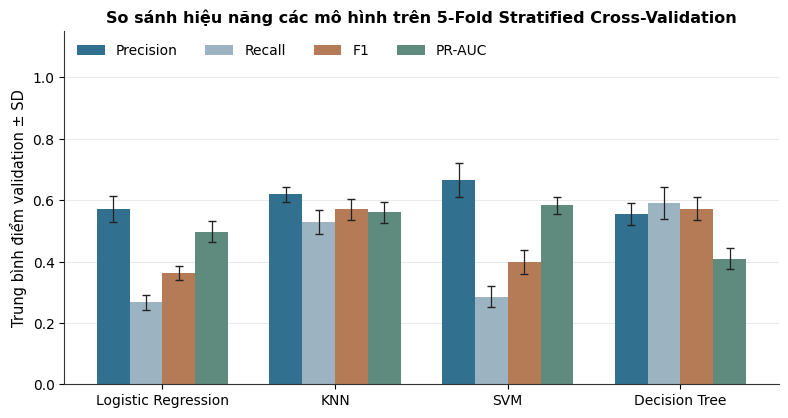

In [13]:
# Biểu đồ minh họa Mục 2.6: Trung bình và SD của các metric qua 5-fold StratifiedKFold
fig, ax = plt.subplots(figsize=(8.0, 4.3))
models_order = ["Logistic Regression", "KNN", "SVM", "Decision Tree"]
df_m = wine_cv_table.loc[models_order]
metrics_2_6 = ["precision", "recall", "f1", "pr_auc"]
labels_2_6 = ["Precision", "Recall", "F1", "PR-AUC"]
x = np.arange(len(models_order))
width = 0.19

for i, (m, lbl) in enumerate(zip(metrics_2_6, labels_2_6)):
    offset = (i - (len(metrics_2_6) - 1) / 2) * width
    ax.bar(x + offset, df_m[f"{m}_mean"], width, yerr=df_m[f"{m}_std"], capsize=3,
           label=lbl, color=PALETTE_MAIN[i], error_kw=dict(ecolor="#222222", lw=0.9))

ax.set_xticks(x)
ax.set_xticklabels(models_order)
ax.set_ylabel("Trung bình điểm validation ± SD")
ax.set_ylim(0, 1.15)
ax.legend(ncol=4, loc="upper left")
style_ax(ax, "y")
plt.title("So sánh hiệu năng các mô hình trên 5-Fold Stratified Cross-Validation")
plt.tight_layout()
plt.show()

## 2.7. Chọn mô hình và đánh giá trên Test

Chọn mô hình có F1 trung bình cao nhất trên Cross Validation. Sau đó fit trên toàn bộ train và đánh giá đúng một lần trên test. Không dùng test để chọn mô hình.

In [14]:
best_wine_name = wine_cv_table["f1_mean"].idxmax()
best_wine_model = wine_models[best_wine_name]
print("Mô hình được chọn theo F1 CV:", best_wine_name)

best_wine_model.fit(X_train_w, y_train_w)
y_pred_w = best_wine_model.predict(X_test_w)
y_prob_w = best_wine_model.predict_proba(X_test_w)[:, 1]

wine_test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test_w, y_pred_w),
    "Precision": precision_score(y_test_w, y_pred_w, zero_division=0),
    "Recall": recall_score(y_test_w, y_pred_w, zero_division=0),
    "F1": f1_score(y_test_w, y_pred_w, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_w, y_prob_w),
    "PR-AUC": average_precision_score(y_test_w, y_prob_w)
}, name="Test score")
display(wine_test_metrics.round(4))

Mô hình được chọn theo F1 CV: Decision Tree


,Test score
Accuracy,0.8554
Precision,0.6298
Recall,0.6445
F1,0.6371
ROC-AUC,0.7758
PR-AUC,0.4759


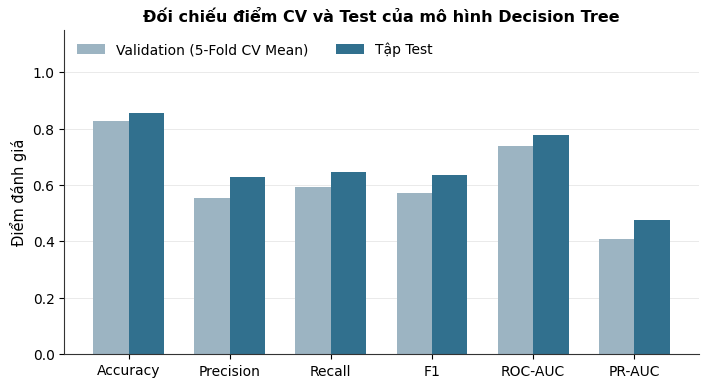

In [15]:
# Biểu đồ minh họa Mục 2.7: So sánh điểm Validation (5-Fold CV) và Test của mô hình tốt nhất
fig, ax = plt.subplots(figsize=(7.2, 4.0))
compare_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
cv_keys = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "pr_auc_mean"]

cv_vals = [wine_cv_table.loc[best_wine_name, k] for k in cv_keys]
test_vals = [wine_test_metrics[m] for m in compare_metrics]

x = np.arange(len(compare_metrics))
width = 0.35

ax.bar(x - width/2, cv_vals, width, label="Validation (5-Fold CV Mean)", color="#9CB4C2")
ax.bar(x + width/2, test_vals, width, label="Tập Test", color="#31708E")

ax.set_xticks(x)
ax.set_xticklabels(compare_metrics)
ax.set_ylabel("Điểm đánh giá")
ax.set_ylim(0, 1.15)
ax.legend(ncol=2, loc="upper left")
style_ax(ax, "y")
plt.title(f"Đối chiếu điểm CV và Test của mô hình {best_wine_name}")
plt.tight_layout()
plt.show()

## 2.8. Confusion Matrix và Classification Report

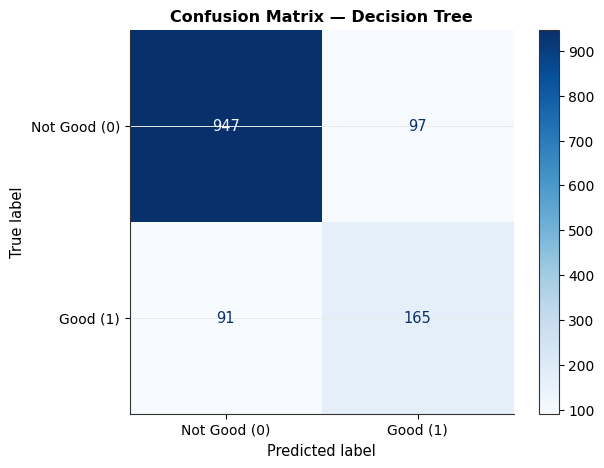

              precision    recall  f1-score   support

Not Good (0)     0.9123    0.9071    0.9097      1044
    Good (1)     0.6298    0.6445    0.6371       256

    accuracy                         0.8554      1300
   macro avg     0.7711    0.7758    0.7734      1300
weighted avg     0.8567    0.8554    0.8560      1300



In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test_w, y_pred_w,
    display_labels=["Not Good (0)", "Good (1)"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_wine_name}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test_w, y_pred_w,
    target_names=["Not Good (0)", "Good (1)"],
    digits=4,
    zero_division=0
))

## 2.9. Precision-Recall Curve

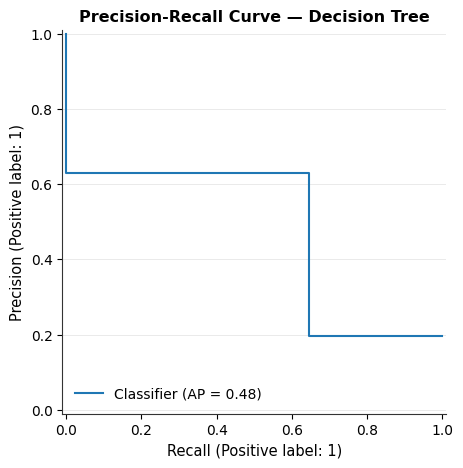

In [17]:
PrecisionRecallDisplay.from_predictions(y_test_w, y_prob_w)
plt.title(f"Precision-Recall Curve — {best_wine_name}")
plt.tight_layout()
plt.show()

## 2.10. Kết luận Bài 2

Dựa trên kết quả notebook sau khi chạy, hãy hoàn thiện nhận xét:

- Mô hình được chọn: xem `best_wine_name`.
- Accuracy: xem bảng `wine_test_metrics`.
- Precision: trong số các mẫu dự đoán Good, tỷ lệ dự đoán đúng là bao nhiêu.
- Recall: trong số rượu Good thực tế, mô hình phát hiện được bao nhiêu.
- F1: cân bằng giữa Precision và Recall.
- PR-AUC: hữu ích khi lớp Good chiếm tỷ lệ thấp.
- Confusion Matrix: quan sát số False Positive và False Negative.

**Lưu ý:** Không ghi trước một con số kết quả cố định; kết quả được sinh ra khi chạy notebook trên dữ liệu và môi trường thư viện thực tế.